<a href="https://colab.research.google.com/github/Uriel1201/Hello-Notebooks/blob/main/python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone https://github.com/Uriel1201/hello-python.git
!git clone https://github.com/Uriel1201/hello-pyplots.git
!python -m pip install uv
%cd hello-python

Cloning into 'hello-python'...
remote: Enumerating objects: 227, done.
remote: Counting objects: 100% (36/36), done.
remote: Compressing objects: 100% (31/31), done.
remote: Total 227 (delta 22), reused 5 (delta 5), pack-reused 191 (from 1)
Receiving objects: 100% (227/227), 102.29 KiB | 2.43 MiB/s, done.
Resolving deltas: 100% (109/109), done.
Cloning into 'hello-pyplots'...
remote: Enumerating objects: 25, done.
remote: Counting objects: 100% (25/25), done.
remote: Compressing objects: 100% (24/24), done.
remote: Total 25 (delta 13), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (25/25), 8.80 KiB | 2.93 MiB/s, done.
Resolving deltas: 100% (13/13), done.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 64.2 MB/s eta 0:00:00
/content/hello-python


## Birthday
Write a program introcs/birthday.py that takes two integer command-line arguments n
and trials and performs the following experiment, trials times:

- Choose a birthday for the next person, uniformly at random between 0 and n−1.
- Have that person enter the room.
- If that person shares a birthday with someone else in the room, stop; otherwise repeat.

In each experiment, count the number of people that enter the room.
Plot an scatterplot that summarizes the results (the number of times that exactly i people
enter the room, and the fraction of times that i or fewer people enter the room)
for each possible value of i from 1 until the fraction reaches (or exceeds) 50%.

### Optimized Simulation Engine
To avoid the bottlenecks inherent to native Python loops in massive executions, the following helper function is implemented, accelerated using Numba:

```python
@njit(cache=True)
def simulate_birthday(n: int, trials: int) -> np.ndarray:
    s = np.zeros(n + 2, dtype=np.int64)
    seen = np.zeros(n, dtype=np.int64)
    for t in range(trials):
        mark = t + 1
        count = 0
        while True:
            p = np.random.randint(0, n)
            count += 1
            if seen[p] == mark:
                break
            seen[p] = mark
        s[count] += 1
    return s
```

### Main

```python
def main() -> None:
    parser = argparse.ArgumentParser()
    parser.add_argument("n", type=int)
    parser.add_argument("trials", type=int)
    args = parser.parse_args()
    n, trials = args.n, args.trials
    if n <= 0 or trials <= 0:
        raise ValueError("Invalid arguments")
    s = simulate_birthday(n, trials)
    p = s / trials
    f = np.cumsum(probabilities[1:n + 2])   
    k = np.searchsorted(f, 0.5)               
    stop = min(k + 1, len(f))                
    for i in range(1, stop + 1):
        print(f"{i}, {s[i]}, {f[i - 1]}")
```

In [4]:
!uv run --script introcs/birthday.py 365 1000000 | env -u MPLBACKEND uv run --script /content/hello-pyplots/plot_birthday.py

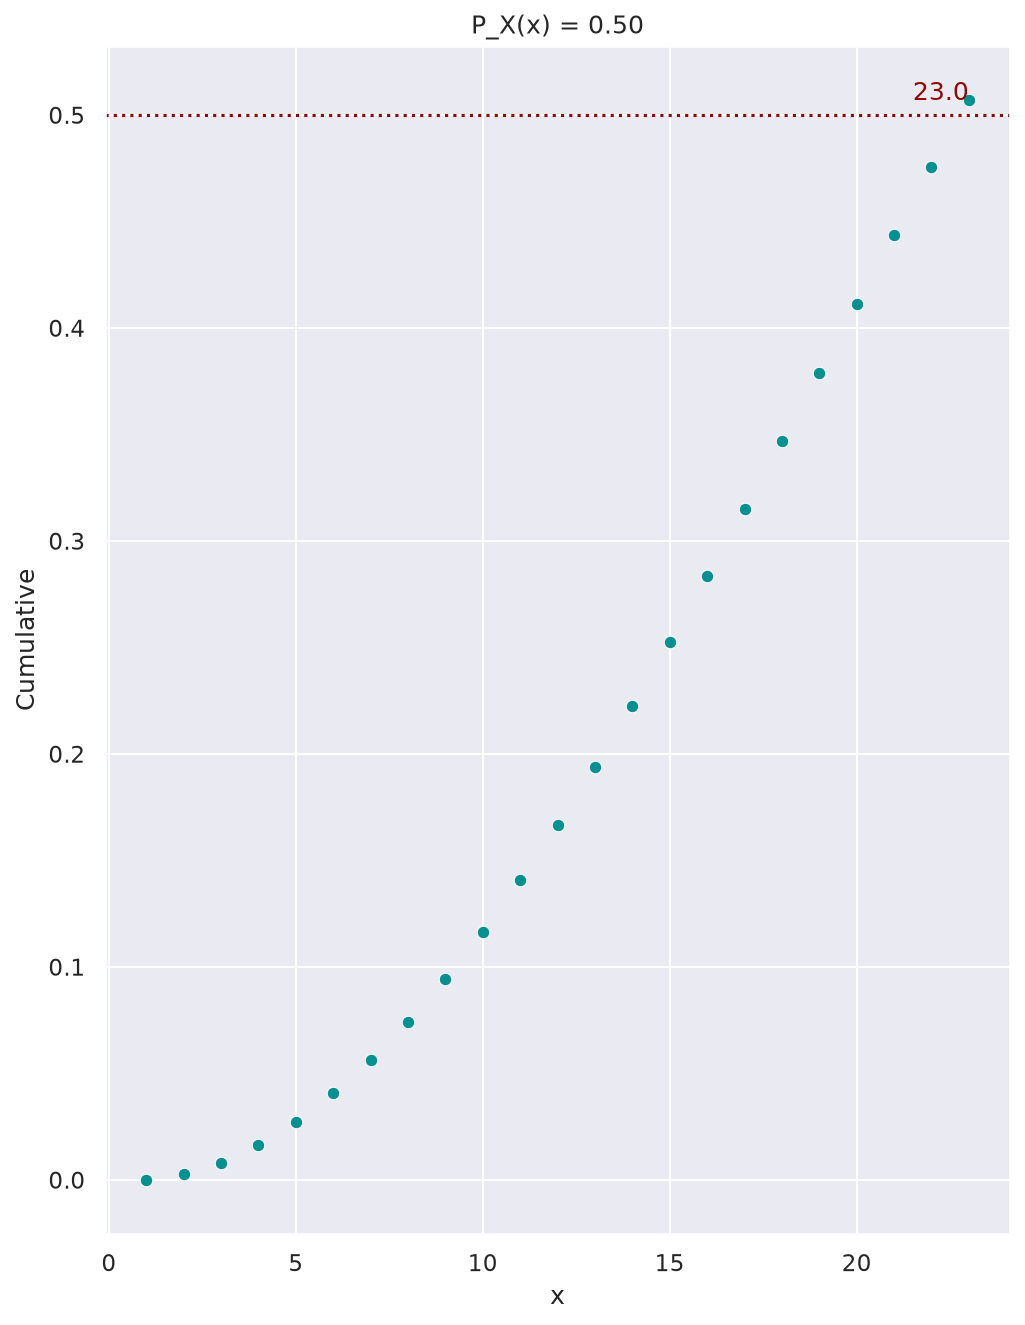

In [5]:
from IPython.display import Image, display
display(Image('images/birthday.png'))

# Discrete Distribution
Write a program introcs/discretedistribution.py that takes an integer command-line
argument `m`, followed by a sequence of positive integer command-line arguments `a1,a2,…,an`
and plots `m` random indices choosing each index `i` with probability proportional to `ai`.

## Main
```python
def main() -> None:
    parser = argparse.ArgumentParser()
    parser.add_argument("args", type=int, nargs="+")
    params = parser.parse_args().args
    if len(params) < 2:
        parser.error("Usage: m a1 a2 ... an")
    m = params.pop(0)
    values = np.array(params, dtype=np.int64)
    if m <= 0 or (values <= 0).any():
        parser.error("m and all a_i must be positive")
    s = np.concatenate(([0], np.cumsum(values)))
    p = np.random.randint(0, s[-1], size=m)
    sample = np.searchsorted(s, p, side="right")
    plot_dist(sample)
```

In [8]:
!uv run introcs/discretedistribution.py 1000000 100 200 50 90 120 300 90 | env -u MPLBACKEND uv run --script /content/hello-pyplots/plot_dist.py

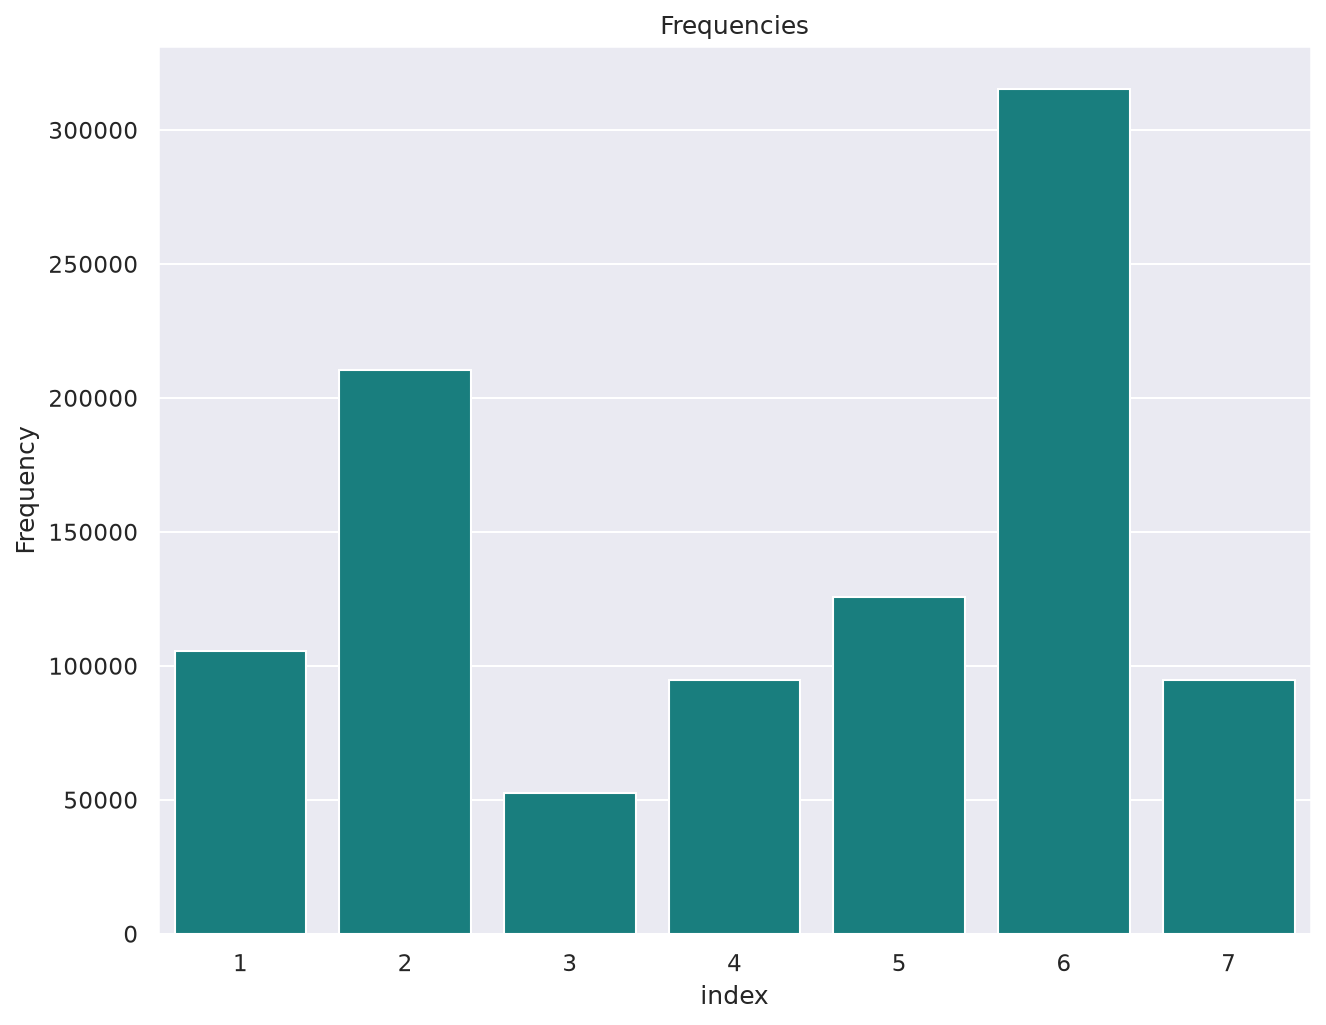

In [9]:
from IPython.display import Image, display
display(Image('images/discret_distribution.png'))